In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("/content/drive/MyDrive/CSV/kc_house_data.csv")


In [4]:
print("Dataset Loaded Successfully")
df.head()

Dataset Loaded Successfully


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [5]:
df.shape

(21613, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [8]:
# Check missing values
print("Missing Values:")
df.isnull().sum()


Missing Values:


,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


In [9]:
# Remove duplicate rows
df = df.drop_duplicates()

In [10]:

# Remove rows with missing important values
required_columns = ['sqft_living', 'price', 'grade',
                    'waterfront', 'lat', 'long']

df = df.dropna(subset=required_columns)



In [11]:
# Remove invalid values
df = df[(df['price'] > 0) & (df['sqft_living'] > 0)]

print("Cleaned Dataset Shape:", df.shape)

Cleaned Dataset Shape: (21613, 21)


Living Area vs House Price (Scatter plot)

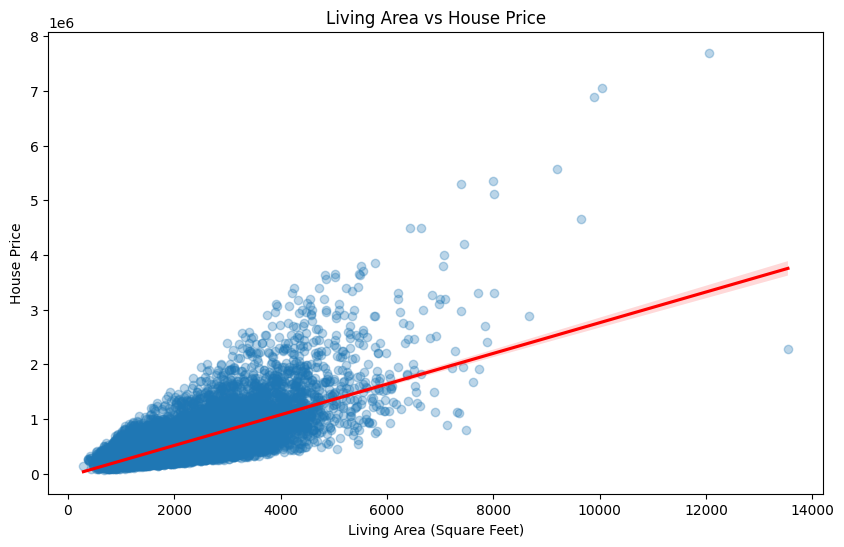

In [12]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='sqft_living',
    y='price',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title('Living Area vs House Price')
plt.xlabel('Living Area (Square Feet)')
plt.ylabel('House Price')
plt.show()

Nonlinear trend visualization

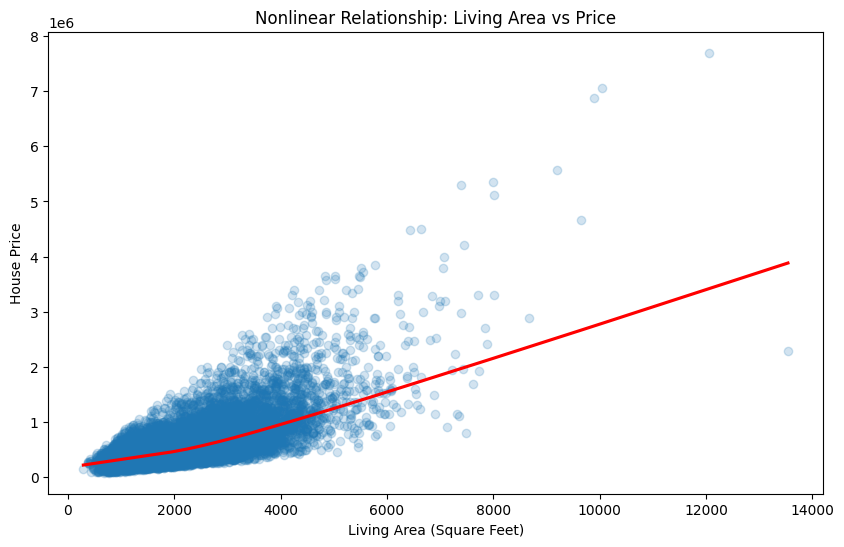

In [13]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='sqft_living',
    y='price',
    lowess=True,
    scatter_kws={'alpha': 0.2},
    line_kws={'color': 'red'}
)

plt.title('Nonlinear Relationship: Living Area vs Price')
plt.xlabel('Living Area (Square Feet)')
plt.ylabel('House Price')
plt.show()

House Price by Property Grade (Box Plot)

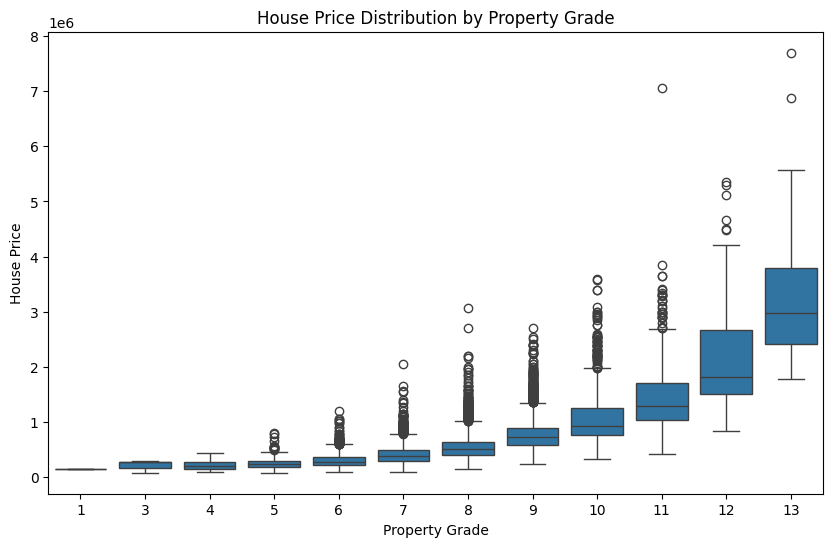

In [14]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='grade',
    y='price'
)

plt.title('House Price Distribution by Property Grade')
plt.xlabel('Property Grade')
plt.ylabel('House Price')
plt.show()

House Price by Waterfront Status

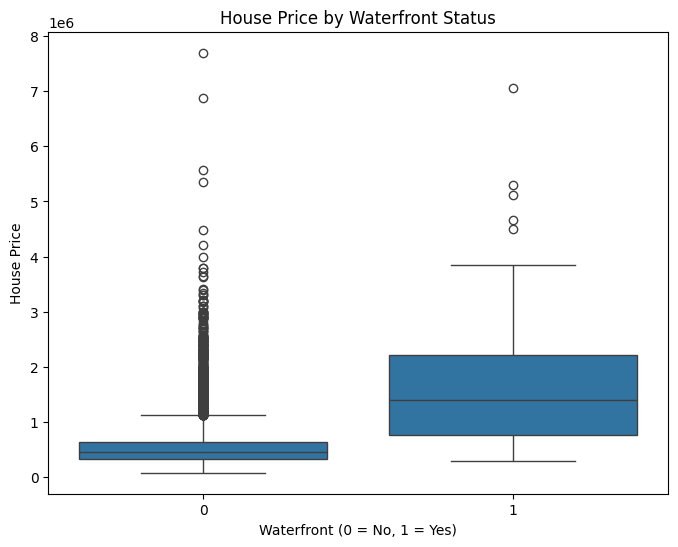

In [15]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x='waterfront',
    y='price'
)

plt.title('House Price by Waterfront Status')
plt.xlabel('Waterfront (0 = No, 1 = Yes)')
plt.ylabel('House Price')
plt.show()

Geographic Price Visualization

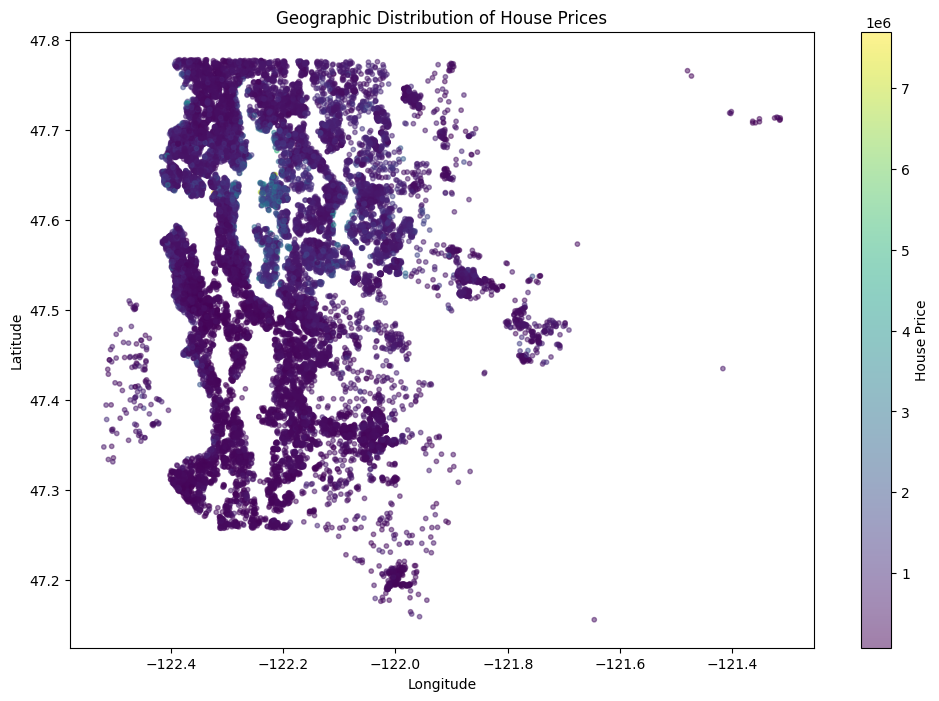

In [16]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df['long'],
    df['lat'],
    c=df['price'],
    cmap='viridis',
    alpha=0.5,
    s=10
)

plt.colorbar(scatter, label='House Price')
plt.title('Geographic Distribution of House Prices')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

Identify High-Value Location Clusters

In [17]:
# Divide locations into geographic groups
df['location_cluster'] = (
    df['lat'].round(2).astype(str) + "_" +
    df['long'].round(2).astype(str)
)

cluster_analysis = df.groupby('location_cluster').agg(
    Average_Price=('price', 'mean'),
    Median_Price=('price', 'median'),
    House_Count=('price', 'count'),
    Average_Living_Area=('sqft_living', 'mean')
).reset_index()

# Consider clusters with at least 10 houses
eligible_clusters = cluster_analysis[
    cluster_analysis['House_Count'] >= 10
]

high_value_clusters = eligible_clusters.sort_values(
    by='Average_Price',
    ascending=False
).head(10)

print("Top 10 High-Value Location Clusters")
print(high_value_clusters.to_string(index=False))

Top 10 High-Value Location Clusters
location_cluster  Average_Price  Median_Price  House_Count  Average_Living_Area
   47.62_-122.24   2.229227e+06     2100000.0           13          3821.923077
   47.62_-122.22   2.124067e+06     1720375.0           26          3811.923077
   47.65_-122.22   1.954960e+06     1898000.0           10          3323.000000
   47.56_-122.21   1.918740e+06     1205000.0           10          4576.000000
   47.63_-122.22   1.872682e+06     1749000.0           17          3612.941176
   47.62_-122.23   1.839385e+06     1650000.0           11          3242.727273
   47.61_-122.21   1.689800e+06     1507500.0           10          3517.000000
   47.63_-122.29   1.663830e+06     1715000.0           25          3492.400000
   47.66_-122.27   1.641694e+06     1575000.0           18          3427.222222
   47.62_-122.21   1.586240e+06     1465000.0           26          2990.000000


Visualize Top High-Value Clusters

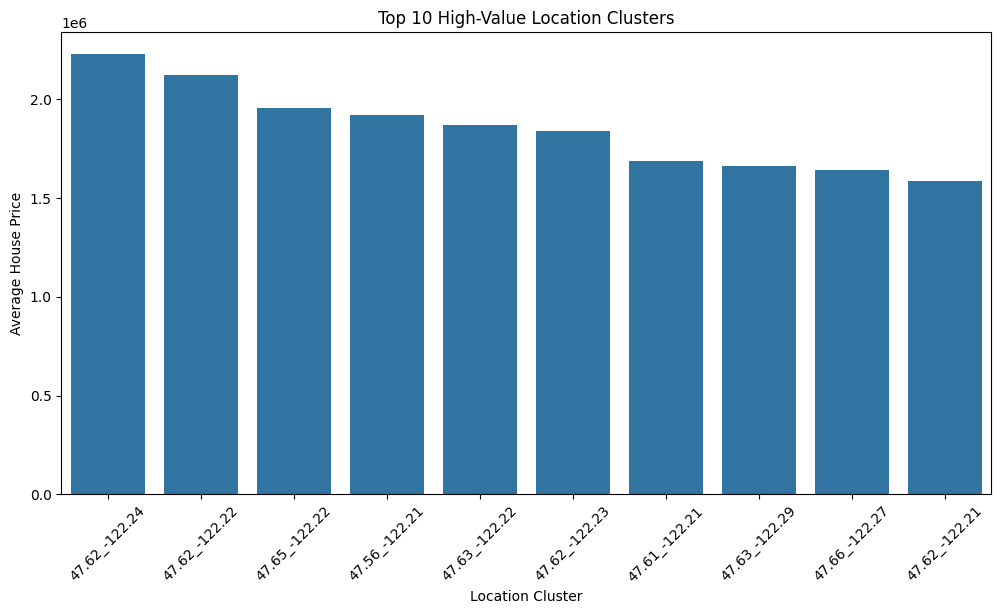

In [18]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=high_value_clusters,
    x='location_cluster',
    y='Average_Price'
)

plt.title('Top 10 High-Value Location Clusters')
plt.xlabel('Location Cluster')
plt.ylabel('Average House Price')
plt.xticks(rotation=45)
plt.show()

Investment Insights

In [19]:
overall_average = df['price'].mean()
overall_median = df['price'].median()

waterfront_average = df.groupby('waterfront')['price'].mean()
grade_average = df.groupby('grade')['price'].mean()

print("REAL ESTATE INVESTMENT INSIGHTS")
print("--------------------------------")

print(f"Total Houses Analyzed: {len(df)}")
print(f"Average House Price: ${overall_average:,.2f}")
print(f"Median House Price: ${overall_median:,.2f}")

print("\nAverage Price by Waterfront Status:")
print(waterfront_average)

print("\nAverage Price by Grade:")
print(grade_average)

print("\nTop High-Value Locations:")
print(high_value_clusters.head(5).to_string(index=False))

REAL ESTATE INVESTMENT INSIGHTS
--------------------------------
Total Houses Analyzed: 21613
Average House Price: $540,088.14
Median House Price: $450,000.00

Average Price by Waterfront Status:
waterfront
0    5.315636e+05
1    1.661876e+06
Name: price, dtype: float64

Average Price by Grade:
grade
1     1.420000e+05
3     2.056667e+05
4     2.143810e+05
5     2.485240e+05
6     3.019196e+05
7     4.025903e+05
8     5.428528e+05
9     7.735132e+05
10    1.071771e+06
11    1.496842e+06
12    2.191222e+06
13    3.709615e+06
Name: price, dtype: float64

Top High-Value Locations:
location_cluster  Average_Price  Median_Price  House_Count  Average_Living_Area
   47.62_-122.24   2.229227e+06     2100000.0           13          3821.923077
   47.62_-122.22   2.124067e+06     1720375.0           26          3811.923077
   47.65_-122.22   1.954960e+06     1898000.0           10          3323.000000
   47.56_-122.21   1.918740e+06     1205000.0           10          4576.000000
   47.63_-122.2

Export analysis results

In [20]:
# Save cleaned dataset
df.to_csv('cleaned_house_data.csv', index=False)

# Save cluster analysis
high_value_clusters.to_csv(
    'high_value_location_clusters.csv',
    index=False
)

print("Files exported successfully!")

Files exported successfully!
